<a href="https://colab.research.google.com/github/J3remy1/east-river-water-quality/blob/main/notebooks/02_dissolved_oxygen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/J3remy1/east-river-water-quality/main/data/ditl_2026-10-06_east_river.csv"
df = pd.read_csv(url)

In [2]:
import numpy as np

def do_saturation(temp_c, salinity_ppt):
    """Dissolved oxygen at saturation, mg/L, 1 atm (Weiss 1970)."""
    T = temp_c + 273.15
    A1, A2, A3, A4 = -173.4292, 249.6339, 143.3483, -21.8492
    B1, B2, B3 = -0.033096, 0.014259, -0.0017000
    ln_c = (A1 + A2 * (100 / T) + A3 * np.log(T / 100) + A4 * (T / 100)
            + salinity_ppt * (B1 + B2 * (T / 100) + B3 * (T / 100) ** 2))
    return np.exp(ln_c) * 1.42903

print(do_saturation(20, 35), do_saturation(0, 0))

7.381790508680555 14.601874777496054


In [3]:
do = df.dropna(subset=["do_ppm"]).copy()
s = df["salinity_ppt"].median()

do["pct_fresh"] = 100 * do["do_ppm"] / do_saturation(do["water_temp_c"], 0)
do["pct_salty"] = 100 * do["do_ppm"] / do_saturation(do["water_temp_c"], s)

do[["group", "trial", "water_temp_c", "do_ppm", "do_sat_reported",
    "pct_fresh", "pct_salty"]].round(0)

,group,trial,water_temp_c,do_ppm,do_sat_reported,pct_fresh,pct_salty
0,A,1,19,8.0,81.0,86.0,102.0
3,B,1,19,8.0,88.0,86.0,102.0
4,B,2,19,9.0,100.0,97.0,114.0
5,B,3,19,9.0,98.0,97.0,114.0
6,C,1,19,19.0,81.0,205.0,242.0
7,C,2,19,9.0,93.0,97.0,114.0
8,C,3,19,9.0,95.0,97.0,114.0
9,D,1,20,9.0,95.0,99.0,117.0
10,D,2,20,5.0,52.0,55.0,65.0
11,D,3,18,9.0,93.0,95.0,112.0


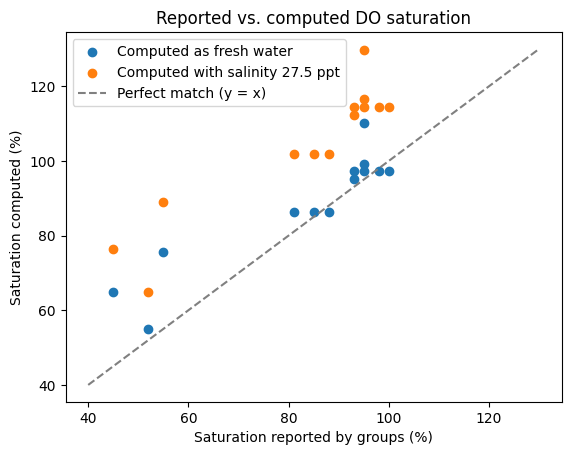

In [4]:
import matplotlib.pyplot as plt

bad = (do["group"] == "C") & (do["trial"] == 1)
ok = do[~bad]

plt.scatter(ok["do_sat_reported"], ok["pct_fresh"], label="Computed as fresh water")
plt.scatter(ok["do_sat_reported"], ok["pct_salty"], label="Computed with salinity 27.5 ppt")
plt.plot([40, 130], [40, 130], linestyle="--", color="gray", label="Perfect match (y = x)")

plt.xlabel("Saturation reported by groups (%)")
plt.ylabel("Saturation computed (%)")
plt.title("Reported vs. computed DO saturation")
plt.legend()
plt.show()

# Findings: dissolved oxygen
The saturation values reported by the groups closely match saturation calculated for fresh water (for example, Group B reported 88%, 100%, and 98%; the freshwater calculation gives 86%, 97%, and 97%). This suggests the groups used a freshwater saturation table, even though the East River is brackish. Because salt lowers how much oxygen water can hold, correcting for salinity (Weiss 1970, using the median salinity of 27.5 ppt) raises saturation by about 15 percentage points: 9 of the 13 readings fall between 102% and 117%. Since the test kit reads only whole numbers, each reading is uncertain by roughly ±1 ppm (about ±13% saturation), so the water was approximately saturated, not clearly supersaturated.

One reading was excluded: Group C, trial 1 (19 ppm), which would mean about 242% saturation and contradicts the group’s own reported 81%. Group F’s reported values are 15 to 21 points below the freshwater calculation, for unknown reasons. Changing the salinity anywhere from 25 to 29 ppt changes the result for an 8 ppm reading by only about 3 points (100% to 103%), so the conclusion does not depend on that choice.

Reference: Weiss, R. F. (1970). The solubility of nitrogen, oxygen and argon in water and seawater. Deep-Sea Research, 17, 721–735.

